# Chapitre 1 - Cours 3 : cas d'usage et planification d'une application d'IA

Ce notebook couvre deux grandes sections du chapitre 1 :

- *Foundation Model Use Cases* : le panorama des usages (code, image et vidéo, écriture,
  éducation, agents conversationnels, agrégation d'information, organisation des données,
  automatisation) et ce qu'ils nous apprennent sur ce que l'IA fait bien ;
- *Planning AI Applications* : faut-il construire cette application ? avec quel rôle pour
  l'IA et pour l'humain ? comment se défendre ? comment fixer des attentes mesurables,
  planifier des jalons réalistes et anticiper la maintenance ?

Le livre est ici très qualitatif ; nous ajoutons des outils quantitatifs : statistiques
pour décider quand automatiser, mesure de latence sur un vrai modèle, modélisation de la
courbe du « dernier kilomètre », analyse construire / acheter avec des prix qui baissent.

Plan :

1. panorama des cas d'usage ;
2. ce que l'IA fait bien : chiffres et mini-démonstrations ;
3. évaluer le cas d'usage (enjeu, rôle de l'IA, rôle de l'humain) ;
4. la défendabilité d'un produit d'IA ;
5. fixer des attentes : métriques métier et seuil d'utilité (qualité, latence, coût) ;
6. planifier les jalons : le dernier kilomètre ;
7. la maintenance dans un domaine qui bouge vite.

In [1]:
import json
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from aie.plotting import (INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN, LIGHT,
                          annotate_bars, finish)
from aie.diagrams import Diagram
from aie import llm
from aie import ch01_introduction as c1

c1.setup_style()
llm.seed_everything(0)
pd.set_option("display.max_colwidth", 200)

## 1. Panorama des cas d'usage (section *Foundation Model Use Cases*)

Classer les usages de l'IA générative est difficile : AWS propose trois catégories
(expérience client, productivité des employés, optimisation des processus), une enquête
O'Reilly en propose huit, Deloitte classe par valeur créée. Le livre, après l'analyse de
205 applications open source et de nombreuses études de cas d'entreprises, retient **huit
catégories**, chacune avec des déclinaisons grand public et entreprise. Une même
application peut relever de plusieurs catégories, puisque les modèles sont généralistes.

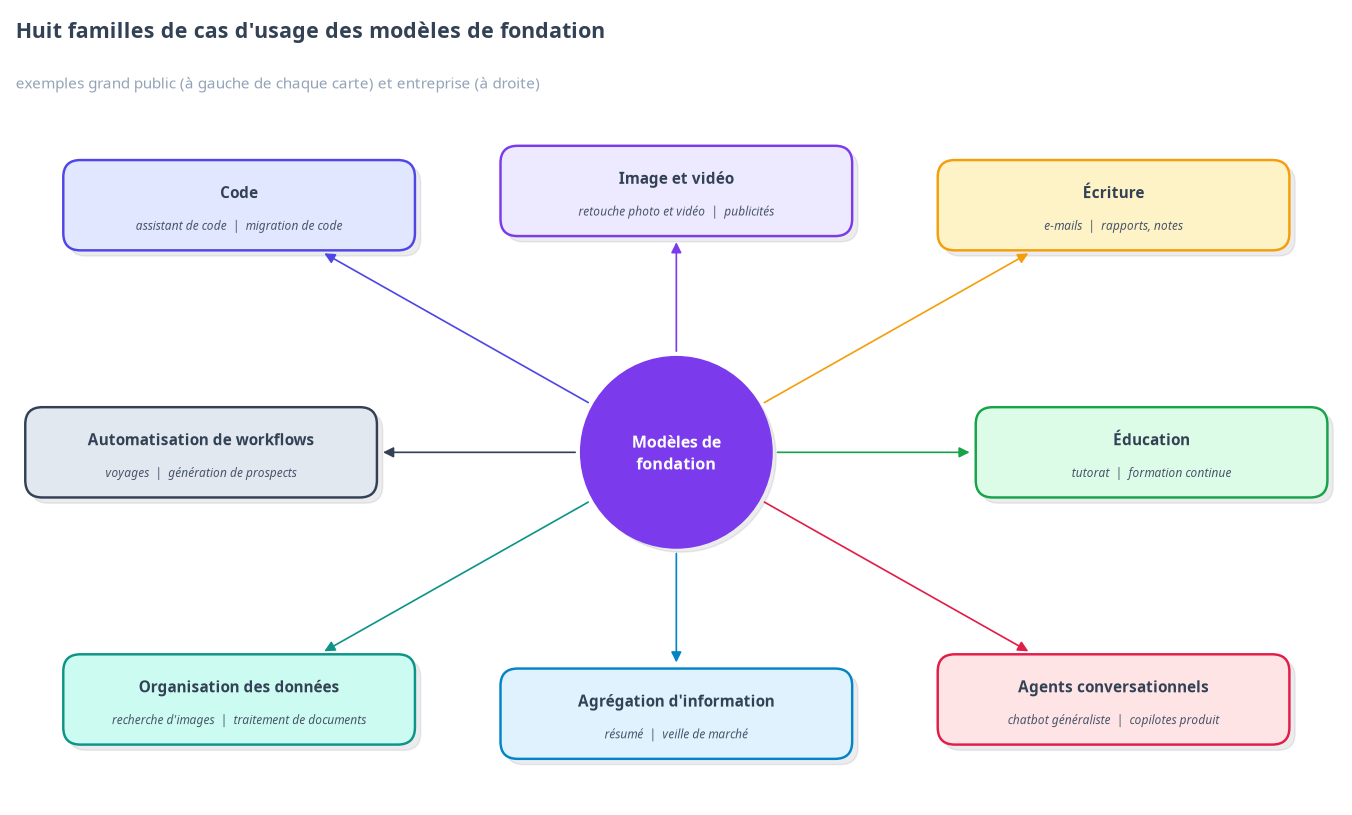

In [2]:
d = Diagram(14, 7.4, title="Huit familles de cas d'usage des modèles de fondation",
            subtitle="exemples grand public (à gauche de chaque carte) et entreprise (à droite)")
cats = list(c1.USE_CASES.items())
palette = [INDIGO, VIOLET, AMBER, GREEN, ROSE, SKY, TEAL, SLATE]
d.box("fm", 7.0, 3.7, "Modèles de\nfondation", color=VIOLET, kind="circle", w=2.0, filled=True)
pos = [(2.4, 6.3), (7.0, 6.45), (11.6, 6.3), (12.0, 3.7), (11.6, 1.1), (7.0, 0.95), (2.4, 1.1), (2.0, 3.7)]
for i, ((cat, (gp, ent)), (x, y), col) in enumerate(zip(cats, pos, palette)):
    d.box(f"c{i}", x, y, cat, sub=f"{gp[0]}  |  {ent[-1]}", color=col, w=3.7, h=0.95, fontsize=10)
    d.arrow("fm", f"c{i}", color=col, lw=1.1)
d.show()

**Ce que l'IA fait bien.** L'étude d'Eloundou et al. (2023), citée par le livre, mesure
l'« exposition » des métiers à l'IA : une tâche est exposée si l'IA permet de réduire d'au
moins 50 % le temps nécessaire pour l'accomplir. Les métiers les plus exposés sont des
métiers de **langage** (traduction, écriture, relations publiques) ; les moins exposés
sont manuels (cuisiniers, tailleurs de pierre, athlètes).

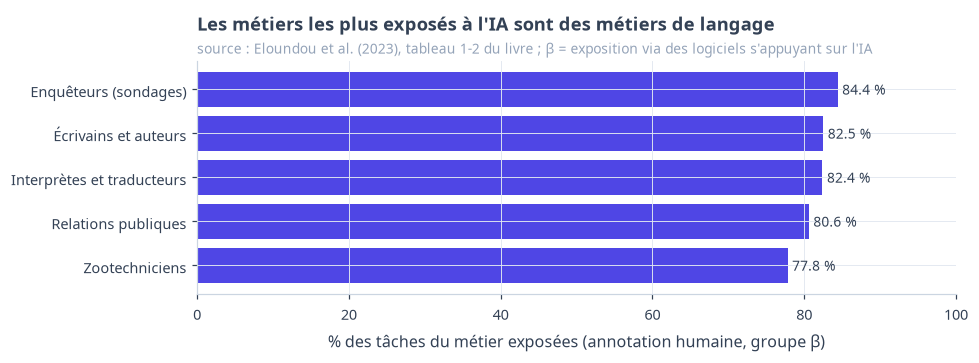

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.4))
occ = list(c1.EXPOSURE_BETA)[::-1]
ax.barh(occ, [c1.EXPOSURE_BETA[o] for o in occ], color=INDIGO)
ax.set_xlim(0, 100)
ax.set_xlabel("% des tâches du métier exposées (annotation humaine, groupe β)")
annotate_bars(ax, "{:.1f} %")
c1.title_sub(ax, "Les métiers les plus exposés à l'IA sont des métiers de langage",
             "source : Eloundou et al. (2023), tableau 1-2 du livre ; β = exposition via des logiciels s'appuyant sur l'IA")
plt.tight_layout(); plt.show()

**Ce que les entreprises déploient d'abord.** Le livre souligne que les entreprises
préfèrent les applications à **faible risque** : internes plutôt qu'exposées aux clients
(une erreur reste dans l'entreprise, la confidentialité est mieux maîtrisée), et à sortie
**fermée** (classification) plutôt qu'ouverte, car plus faciles à évaluer. Positionnons
quelques usages sur ces deux axes (placement qualitatif, à titre d'illustration).

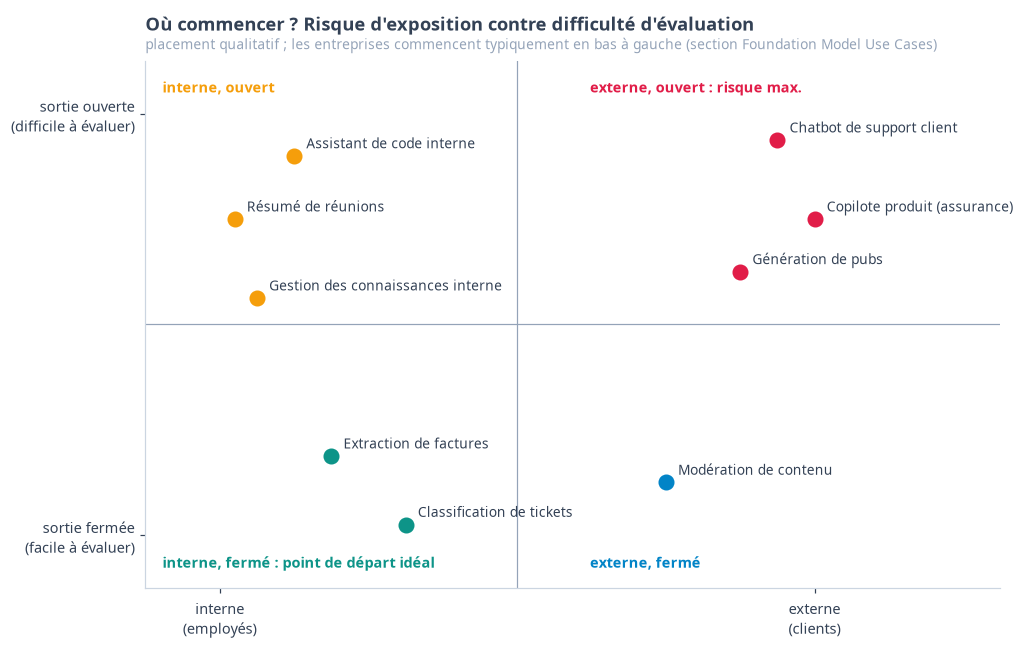

In [4]:
uses = {
    "Gestion des connaissances interne": (0.15, 0.55), "Classification de tickets": (0.35, 0.12),
    "Extraction de factures": (0.25, 0.25), "Résumé de réunions": (0.12, 0.7),
    "Assistant de code interne": (0.2, 0.82), "Chatbot de support client": (0.85, 0.85),
    "Modération de contenu": (0.7, 0.2), "Génération de pubs": (0.8, 0.6),
    "Copilote produit (assurance)": (0.9, 0.7),
}
fig, ax = plt.subplots(figsize=(9.5, 6))
ax.axhline(0.5, color=GRAY, lw=0.8); ax.axvline(0.5, color=GRAY, lw=0.8)
for (x0, y0, txt, col) in [(0.02, 0.97, "interne, ouvert", AMBER), (0.52, 0.97, "externe, ouvert : risque max.", ROSE),
                           (0.02, 0.03, "interne, fermé : point de départ idéal", TEAL), (0.52, 0.03, "externe, fermé", SKY)]:
    ax.text(x0, y0, txt, transform=ax.transAxes, fontsize=9.5, fontweight="bold", color=col,
            va="top" if y0 > 0.5 else "bottom")
for k, (x, y) in uses.items():
    col = TEAL if (x < 0.5 and y < 0.5) else ROSE if (x > 0.5 and y > 0.5) else AMBER if x < 0.5 else SKY
    ax.scatter(x, y, s=90, color=col, zorder=5)
    ax.annotate(k, (x, y), textcoords="offset points", xytext=(8, 5), fontsize=9)
ax.set_xlim(0, 1.15); ax.set_ylim(0, 1)
ax.set_xticks([0.1, 0.9], ["interne\n(employés)", "externe\n(clients)"])
ax.set_yticks([0.1, 0.9], ["sortie fermée\n(facile à évaluer)", "sortie ouverte\n(difficile à évaluer)"])
ax.grid(False)
c1.title_sub(ax, "Où commencer ? Risque d'exposition contre difficulté d'évaluation",
             "placement qualitatif ; les entreprises commencent typiquement en bas à gauche (section Foundation Model Use Cases)")
plt.tight_layout(); plt.show()

> **À retenir.** Huit grandes familles d'usages ; l'IA excelle dans les tâches de langage
> et d'information. Les entreprises commencent par des applications internes et fermées,
> plus faciles à évaluer, pour construire leur expertise à moindre risque.

## 2. Ce que l'IA fait bien : chiffres et mini-démonstrations (sections *Coding* à *Workflow Automation*)

**Productivité mesurée.** Deux études citées par le livre donnent des ordres de grandeur :

- McKinsey : les développeurs assistés par l'IA sont environ **deux fois** plus rapides
  pour la documentation, 25 à 50 % plus rapides pour générer ou refactoriser du code, mais
  le gain est minime pour les tâches très complexes ;
- Noy et Zhang (MIT, 2023), sur 453 professionnels : avec ChatGPT, le temps des tâches
  d'écriture baisse de **40 %** et la qualité augmente de **18 %**.

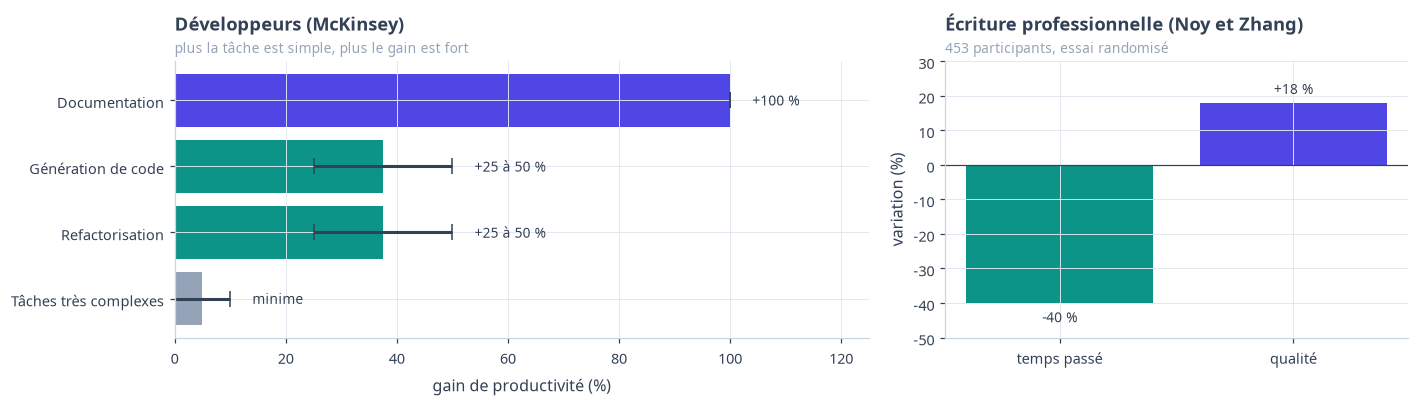

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1.5, 1]})
tasks_mck = ["Documentation", "Génération de code", "Refactorisation", "Tâches très complexes"]
lo = np.array([100, 25, 25, 0]); hi = np.array([100, 50, 50, 10])
mid = (lo + hi) / 2
axes[0].barh(tasks_mck[::-1], mid[::-1], xerr=[(mid - lo)[::-1], (hi - mid)[::-1]], color=[GRAY, TEAL, TEAL, INDIGO],
             capsize=5, ecolor=SLATE)
for i, (a, b) in enumerate(zip(lo[::-1], hi[::-1])):
    axes[0].text(max(b, 5) + 4, i, f"+{a} %" if a == b else (f"+{a} à {b} %" if a else "minime"), va="center", fontsize=9)
axes[0].set_xlim(0, 125)
axes[0].set_xlabel("gain de productivité (%)")
c1.title_sub(axes[0], "Développeurs (McKinsey)", "plus la tâche est simple, plus le gain est fort")
axes[1].bar(["temps passé", "qualité"], [-40, 18], color=[TEAL, INDIGO])
axes[1].axhline(0, color=SLATE, lw=0.8)
annotate_bars(axes[1], "{:+.0f} %")
axes[1].set_ylabel("variation (%)")
axes[1].set_ylim(-50, 30)
c1.title_sub(axes[1], "Écriture professionnelle (Noy et Zhang)", "453 participants, essai randomisé")
finish(fig); plt.show()

**Mini-démonstration 1 : agrégation d'information.** Le livre raconte que chez Instacart,
l'un des gabarits de prompt les plus populaires, « Fast Breakdown », résume des notes de
réunion en **faits**, **questions ouvertes** et **actions**. Essayons-le avec
Qwen2.5-0.5B sur des notes de réunion fictives.

In [6]:
notes = """Réunion produit du mardi. Présents : Léa (PM), Karim (backend), Sofia (data).
Le taux de résolution automatique du chatbot est passé de 41 % à 47 % depuis le nouveau prompt.
Karim signale que la latence p95 dépasse 4 secondes aux heures de pointe.
Sofia propose d'ajouter 200 conversations annotées au jeu d'évaluation, mais personne ne sait qui paiera l'annotation.
Léa doit présenter les résultats au comité vendredi. Karim testera un modèle plus petit d'ici jeudi."""
fast_breakdown = ("Résume ces notes de réunion en trois rubriques : « Faits », « Questions ouvertes », "
                  "« Actions (responsable, échéance) ». Sois bref.\n\n" + notes)
fb = llm.chat(fast_breakdown, llm.SMALL, max_new_tokens=220)
print(fb[:1200])

Voici une résumée des points principaux de cette réunion :

- Le taux de résolution automatique du chatbot a été modifié de 41% à 47% depuis le nouveau prompt.
  
- La latence p95 pour les messages d'entraînement atteint 4 secondes aux heures de pointe.
  
- Sofia propose d'ajouter 200 conversations annotées au jeu d'évaluation, mais personne ne sait qui paiera l'annotation.
  
- Léa doit présenter les résultats au comité vendredi.
  
- Karim testera un modèle plus petit d'ici jeudi.


Vérifiez la sortie contre les notes, comme le ferait un évaluateur. Ce petit modèle
retrouve bien les faits chiffrés et les deux actions (présentation de Léa vendredi, test de
Karim jeudi), mais il ne respecte pas forcément la **structure** demandée (une seule liste
au lieu de trois rubriques) et peut glisser un détail **inexact** (relisez la phrase sur la
latence). C'est la grande force de l'agrégation d'information : la tâche reste utile même
imparfaite, car un humain relit vite un résumé. Le livre note que ces actions peuvent
ensuite être insérées automatiquement dans un outil de suivi : on glisse alors vers
l'automatisation, et l'exigence de fiabilité monte d'un cran.

**Mini-démonstration 2 : organisation des données.** Extraire des informations
structurées de données non structurées est un cas d'usage d'entreprise majeur (le livre
cite un marché du traitement intelligent de documents estimé à 12,8 Md$ en 2030). Le
critère de succès est ici **vérifiable** : le JSON est-il valide, les champs sont-ils
justes ?

In [7]:
signatures = [
    "Cordialement,\nMarie Dupont\nResponsable achats - Boulangeries Levain SAS\nTél. 04 72 11 22 33\nmarie.dupont@levain.fr",
    "Bien à vous,\nDr Ahmed Benali, cardiologue\nClinique du Parc, 12 rue des Lilas, 69006 Lyon\n+33 4 78 00 11 22",
    "--\nTom Martin | CTO @ Nuage Rouge\ntom@nuagerouge.io | nuagerouge.io",
]
truth = [{"nom": "Marie Dupont", "entreprise": "Boulangeries Levain SAS"},
         {"nom": "Ahmed Benali", "entreprise": "Clinique du Parc"},
         {"nom": "Tom Martin", "entreprise": "Nuage Rouge"}]
def extract(sig, model_id):
    prompt = ("Extrais de cette signature d'e-mail un objet JSON avec les clés "
              "\"nom\", \"entreprise\", \"email\" et \"telephone\" (null si absent). Réponds uniquement par le JSON.\n\n" + sig)
    raw = llm.chat(prompt, model_id, max_new_tokens=120)
    m = re.search(r"\{.*\}", raw, re.S)
    try:
        obj = json.loads(m.group(0)) if m else None
    except json.JSONDecodeError:
        obj = None
    return raw, obj

def fields_ok(obj, t):
    return obj is not None and all(v.lower() in str(obj.get(k) or "").lower() for k, v in t.items())

rows, score = [], {}
for name, mid in [("Qwen2.5-0.5B", llm.SMALL), ("Qwen2.5-1.5B", llm.MEDIUM)]:
    res = [extract(sig, mid) for sig in signatures]
    score[name] = (sum(o is not None for _, o in res), sum(fields_ok(o, t) for (_, o), t in zip(res, truth)))
    if mid == llm.SMALL:
        rows = [{"signature (début)": sig.splitlines()[1][:32], "JSON valide": o is not None,
                 "nom et entreprise corrects": fields_ok(o, t), "sortie de Qwen2.5-0.5B (tronquée)": re.sub(r"\s+", " ", raw)[:120]}
                for sig, (raw, o), t in zip(signatures, res, truth)]
llm.free_gpu()  # libère le modèle 1,5 Md (GPU partagé)
display(pd.DataFrame(rows))
pd.DataFrame(score, index=["JSON valides (sur 3)", "nom + entreprise corrects (sur 3)"])

# Le résultat est instructif : le modèle de 0,5 Md produit du JSON **valide** mais remplit
# mal les champs (nom manquant, téléphone rangé dans « email »...) ; le modèle de 1,5 Md fait
# un peu mieux mais reste loin du compte sur ces signatures pourtant simples (un modèle plus
# gros, des exemples dans le prompt ou une sortie contrainte feraient la différence). L'extraction structurée est un bon cas d'école : la sortie se
# **vérifie automatiquement** (validité du JSON, comparaison champ par champ), ce qui la
# rend beaucoup plus facile à évaluer qu'une rédaction libre ; une erreur est **détectée**
# au lieu de passer inaperçue, et la comparaison de modèles devient objective. Le chapitre 5 montre comment fiabiliser ces sorties structurées.
#
# > **À retenir.** Les gains mesurés sont réels (−40 % de temps d'écriture, ×2 pour la
# > documentation) mais concentrés sur les tâches simples. Les usages les plus sûrs sont ceux
# > où une erreur est peu coûteuse (résumé relu par un humain) ou facilement détectable
# > (extraction vérifiable).

,signature (début),JSON valide,nom et entreprise corrects,sortie de Qwen2.5-0.5B (tronquée)
0,Marie Dupont,True,False,"```json { ""nom"": null, ""entreprise"": ""Boulangeries Levain SAS"", ""email"": null, ""telephone"": null } ```"
1,"Dr Ahmed Benali, cardiologue",True,False,"```json { ""nom"": ""Dr Ahmed Benali"", ""entreprise"": null, ""email"": ""+33 4 78 00 11 22"", ""telephone"": null } ```"
2,Tom Martin | CTO @ Nuage Rouge,True,False,"```json { ""nom"": ""Tom Martin"", ""entreprise"": null, ""email"": ""tom@nuagerouge.io"", ""telephone"": null } ```"


,Qwen2.5-0.5B,Qwen2.5-1.5B
JSON valides (sur 3),3,3
nom + entreprise corrects (sur 3),0,1


## 3. Évaluer le cas d'usage (section *Use Case Evaluation*)

**Pourquoi construire ?** Le livre classe les motivations par niveau de risque décroissant.

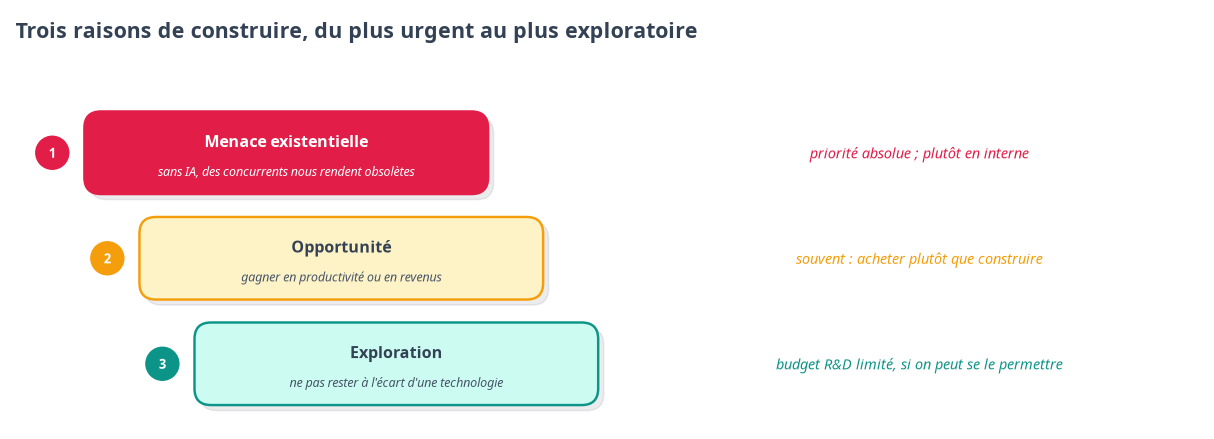

In [8]:
d = Diagram(13, 4.0, title="Trois raisons de construire, du plus urgent au plus exploratoire")
lv = [("Menace existentielle", "sans IA, des concurrents nous rendent obsolètes", ROSE,
       "priorité absolue ; plutôt en interne"),
      ("Opportunité", "gagner en productivité ou en revenus", AMBER, "souvent : acheter plutôt que construire"),
      ("Exploration", "ne pas rester à l'écart d'une technologie", TEAL, "budget R&D limité, si on peut se le permettre")]
for i, (t, sub, col, note) in enumerate(lv):
    y = 3.0 - i * 1.15
    d.box(f"l{i}", 3.0 + i * 0.6, y, t, sub=sub, color=col, w=4.4, h=0.9, filled=(i == 0))
    d.note(9.9, y, note, color=col, fontsize=9.5)
    d.badge(0.45 + i * 0.6, y, str(i + 1), color=col)
d.show()

**Quel rôle pour l'IA ?** Le livre reprend trois distinctions proposées par Apple :

- **critique ou complémentaire** : l'application fonctionne-t-elle sans l'IA ? Plus l'IA
  est critique, plus elle doit être fiable (Face ID contre Smart Compose de Gmail) ;
- **réactive ou proactive** : répond-elle à une demande (chatbot), ou intervient-elle
  d'elle-même (alerte trafic) ? Le réactif exige de la rapidité ; le proactif peut être
  précalculé, mais doit être de **meilleure qualité**, car non sollicité ;
- **dynamique ou statique** : est-elle mise à jour en continu avec les retours de
  l'utilisateur (personnalisation, mémoire), ou périodiquement ?

Ces trois axes se traduisent directement en exigences d'ingénierie.

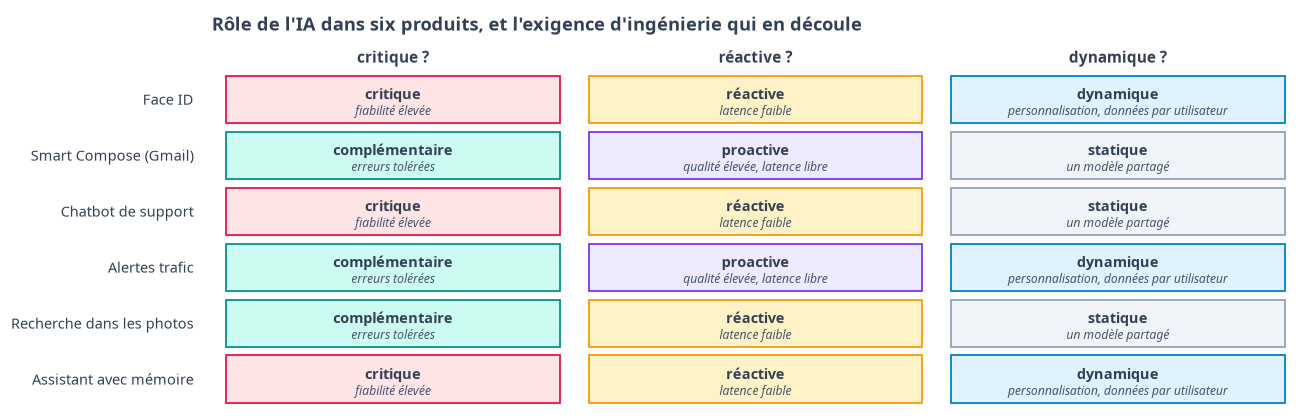

In [9]:
apps = pd.DataFrame([
    ("Face ID", "critique", "réactive", "dynamique"),
    ("Smart Compose (Gmail)", "complémentaire", "proactive", "statique"),
    ("Chatbot de support", "critique", "réactive", "statique"),
    ("Alertes trafic", "complémentaire", "proactive", "dynamique"),
    ("Recherche dans les photos", "complémentaire", "réactive", "statique"),
    ("Assistant avec mémoire", "critique", "réactive", "dynamique"),
], columns=["application", "critique ?", "réactive ?", "dynamique ?"]).set_index("application")
req = {"critique": "fiabilité élevée", "complémentaire": "erreurs tolérées",
       "réactive": "latence faible", "proactive": "qualité élevée, latence libre",
       "dynamique": "personnalisation, données par utilisateur", "statique": "un modèle partagé"}
colors_map = {"critique": ROSE, "complémentaire": TEAL, "réactive": AMBER, "proactive": VIOLET,
              "dynamique": SKY, "statique": GRAY}
fig, ax = plt.subplots(figsize=(12, 3.9))
ax.set_xlim(0, 3); ax.set_ylim(0, len(apps) + 0.45); ax.axis("off")
for j, col in enumerate(apps.columns):
    ax.text(j + 0.5, len(apps) + 0.15, col, ha="center", fontweight="bold", fontsize=10)
    for i, (app, val) in enumerate(apps[col].items()):
        y = len(apps) - 1 - i
        c = colors_map[val]
        ax.add_patch(plt.Rectangle((j + 0.04, y + 0.08), 0.92, 0.84, facecolor=LIGHT[c], edgecolor=c, lw=1.2))
        ax.text(j + 0.5, y + 0.6, val, ha="center", va="center", fontsize=9.5, fontweight="bold", color=SLATE)
        ax.text(j + 0.5, y + 0.3, req[val], ha="center", va="center", fontsize=8, color="#475569", style="italic")
for i, app in enumerate(apps.index):
    ax.text(-0.05, len(apps) - 1 - i + 0.5, app, ha="right", va="center", fontsize=9.5)
ax.set_title("Rôle de l'IA dans six produits, et l'exigence d'ingénierie qui en découle", pad=10)
plt.tight_layout(); plt.show()

**Quel rôle pour l'humain ?** Pour un chatbot de support, l'IA peut proposer des réponses
à un agent humain, ne traiter que les demandes simples, ou répondre à tout. Impliquer
l'humain dans la décision s'appelle **human-in-the-loop**. Microsoft propose d'augmenter
l'automatisation par étapes (*Crawl-Walk-Run*) : humain obligatoire, puis interaction
directe avec les employés, puis avec les clients externes.

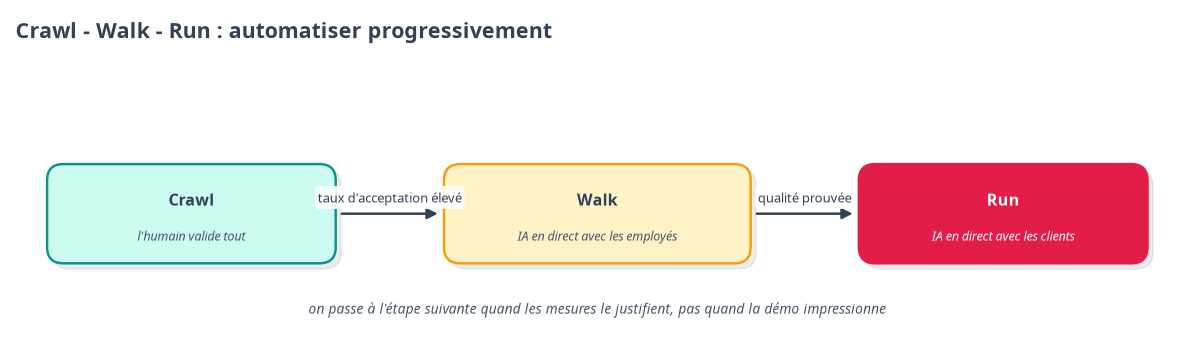

In [10]:
d = Diagram(13, 3.2, title="Crawl - Walk - Run : automatiser progressivement")
d.box("c", 2.0, 1.5, "Crawl", sub="l'humain valide tout", color=TEAL, w=3.2, h=1.1)
d.box("w", 6.5, 1.5, "Walk", sub="IA en direct avec les employés", color=AMBER, w=3.4, h=1.1)
d.box("r", 11.0, 1.5, "Run", sub="IA en direct avec les clients", color=ROSE, w=3.2, h=1.1, filled=True)
d.arrow("c", "w", "taux d'acceptation élevé")
d.arrow("w", "r", "qualité prouvée")
d.note(6.5, 0.45, "on passe à l'étape suivante quand les mesures le justifient, pas quand la démo impressionne")
d.show()

**Quand passer à l'étape suivante ? Un peu de statistiques.** Le livre donne un critère :
si 95 % des réponses suggérées pour les demandes simples sont reprises telles quelles par
les agents, on peut laisser les clients interagir directement avec l'IA. Mais un taux
**observé** de 97 % sur 50 suggestions prouve-t-il que le vrai taux dépasse 95 % ? On
utilise un **intervalle de confiance** pour une proportion ; celui de Wilson se comporte
bien près de 0 et 1 :
$$\frac{\hat p + \frac{z^2}{2n} \pm z\sqrt{\frac{\hat p(1-\hat p)}{n} + \frac{z^2}{4n^2}}}{1 + \frac{z^2}{n}},
  \qquad \hat p = k/n.$$
On ne bascule que si la **borne basse** dépasse le seuil.

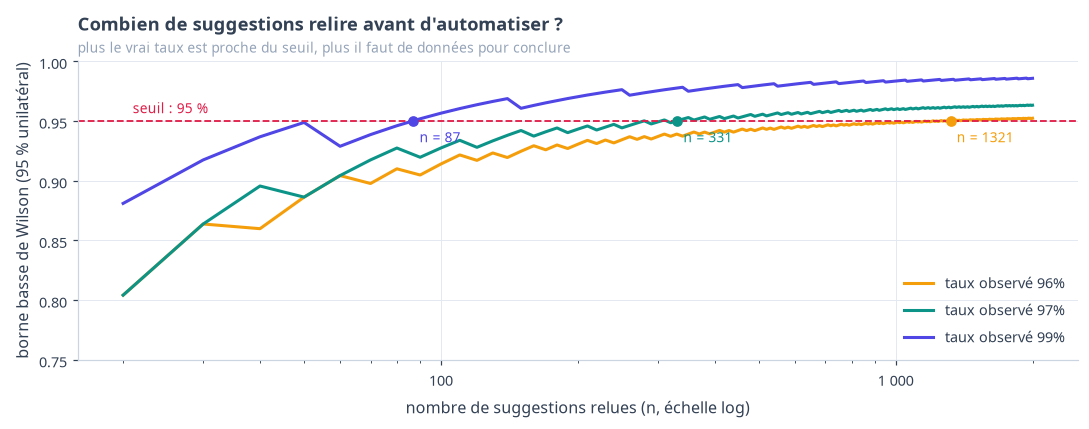

In [11]:
ns = np.arange(20, 2001, 10)
fig, ax = plt.subplots(figsize=(10, 4))
for p_obs, col in [(0.96, AMBER), (0.97, TEAL), (0.99, INDIGO)]:
    lows = [c1.wilson_interval(round(p_obs * n), n, z=1.645)[0] for n in ns]
    ax.plot(ns, lows, color=col, label=f"taux observé {p_obs:.0%}")
    n_req = c1.samples_to_certify(p_obs, 0.95)
    if n_req > 0 and n_req <= ns[-1]:
        ax.scatter([n_req], [0.95], color=col, zorder=5)
        ax.annotate(f"n = {n_req}", (n_req, 0.95), textcoords="offset points", xytext=(4, -14), fontsize=9, color=col)
ax.axhline(0.95, color=ROSE, ls="--", lw=1.2)
ax.text(21, 0.953, "seuil : 95 %", color=ROSE, ha="left", va="bottom", fontsize=9)
ax.set_xscale("log"); c1.plain_log(ax, "x")
ax.set_xlabel("nombre de suggestions relues (n, échelle log)")
ax.set_ylabel("borne basse de Wilson (95 % unilatéral)")
ax.set_ylim(0.75, 1.0)
ax.legend(loc="lower right")
c1.title_sub(ax, "Combien de suggestions relire avant d'automatiser ?",
             "plus le vrai taux est proche du seuil, plus il faut de données pour conclure")
plt.tight_layout(); plt.show()

Avec un taux observé de 99 %, moins d'une centaine de suggestions suffisent ; à 97 %, il en faut
plusieurs centaines ; à 96 %, plus d'un millier. Un tableau de bord qui affiche « 97 %
d'acceptation sur 50 suggestions » ne justifie **pas** encore le passage à *Run*.

> **À retenir.** Avant de construire : pourquoi (menace, opportunité, exploration) ? quel
> rôle pour l'IA (critique, proactive, dynamique ?) et pour l'humain ? On augmente
> l'automatisation par étapes, sur la foi de mesures statistiquement solides.

## 4. La défendabilité d'un produit d'IA (section *AI product defensibility*)

La barrière d'entrée basse est « une bénédiction et une malédiction » : ce qui est facile
à construire pour vous l'est aussi pour vos concurrents. Construire sur un modèle de
fondation, c'est fournir une **couche** au-dessus de ce modèle ; si le modèle progresse,
votre couche peut devenir inutile (l'exemple du livre : un service d'analyse de PDF
au-dessus d'un modèle qui finit par lire les PDF lui-même). Le livre distingue trois
avantages concurrentiels : **technologie**, **données**, **distribution**.

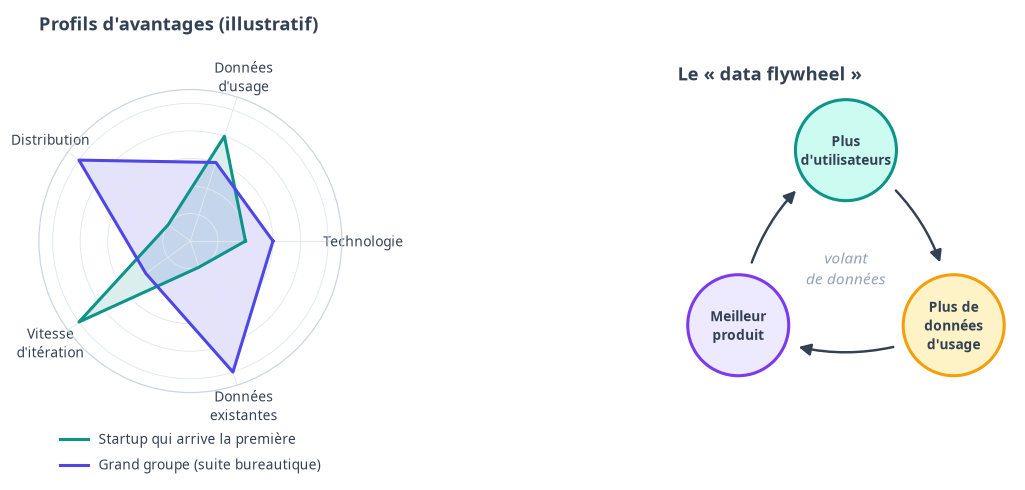

In [12]:
axes_names = ["Technologie", "Données\nd'usage", "Distribution", "Vitesse\nd'itération", "Données\nexistantes"]
profiles = {"Startup qui arrive la première": [2, 4, 1, 5, 1], "Grand groupe (suite bureautique)": [3, 3, 5, 2, 5]}
ang = np.linspace(0, 2 * np.pi, len(axes_names), endpoint=False).tolist()
fig = plt.figure(figsize=(12, 4.6))
ax = fig.add_subplot(1, 2, 1, polar=True)
for (name, vals), col in zip(profiles.items(), [TEAL, INDIGO]):
    v = vals + vals[:1]
    ax.plot(ang + ang[:1], v, color=col, lw=2, label=name)
    ax.fill(ang + ang[:1], v, color=col, alpha=0.15)
ax.set_xticks(ang, axes_names, fontsize=9)
ax.set_yticks([1, 2, 3, 4, 5], [""] * 5); ax.set_ylim(0, 5.5)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), fontsize=9)
ax.set_title("Profils d'avantages (illustratif)", pad=18)
ax2 = fig.add_subplot(1, 2, 2); ax2.axis("off")
ax2.set_xlim(0, 1); ax2.set_ylim(0.1, 1.0); ax2.set_aspect("equal")
from matplotlib.patches import FancyArrowPatch, Circle
labels_fw = ["Plus\nd'utilisateurs", "Plus de\ndonnées\nd'usage", "Meilleur\nproduit"]
cols_fw = [TEAL, AMBER, VIOLET]
pts = [(0.5, 0.82), (0.82, 0.3), (0.18, 0.3)]
for (x, y), lab, col in zip(pts, labels_fw, cols_fw):
    ax2.add_patch(Circle((x, y), 0.15, facecolor=LIGHT[col], edgecolor=col, lw=2))
    ax2.text(x, y, lab, ha="center", va="center", fontsize=9, fontweight="bold")
for i in range(3):
    (x1, y1), (x2, y2) = pts[i], pts[(i + 1) % 3]
    ax2.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=16,
                                  connectionstyle="arc3,rad=-0.25", shrinkA=42, shrinkB=42, color=SLATE, lw=1.6))
ax2.text(0.5, 0.47, "volant\nde données", ha="center", va="center", fontsize=10, color=GRAY, style="italic")
ax2.set_title("Le « data flywheel »", loc="left")
finish(fig); plt.show()

Avec des modèles de fondation, la **technologie** de base est la même pour tous et la
**distribution** appartient plutôt aux grands groupes. L'avantage des **données** est plus
subtil : une startup qui arrive la première peut accumuler des données d'usage qui
améliorent son produit, qui attire plus d'utilisateurs, et ainsi de suite (le « volant de
données », expression que l'auteur dit avoir entendue dans presque toutes ses
conversations avec des startups). Le livre rappelle que Calendly, Mailchimp ou Photoroom
auraient pu n'être que des fonctionnalités de produits plus gros.

> **À retenir.** Ce qui est facile à construire est facile à copier. Les avantages
> durables viennent des données d'usage (volant de données) et de la distribution, pas du
> modèle, que tout le monde partage.

## 5. Fixer des attentes (section *Setting Expectations*)

**Commencer par la métrique métier.** Pour un chatbot de support : quelle part des messages
automatiser ? combien de messages en plus traiter ? quel gain de temps de réponse ? quelle
économie de travail humain ? Sans oublier la **satisfaction client** : répondre à plus de
messages ne veut pas dire satisfaire plus de clients.

**Puis le seuil d'utilité** : à partir de quand le produit est-il assez bon pour être mis
entre les mains des utilisateurs ? Le livre cite quatre familles de métriques : qualité,
**latence** (TTFT, *time to first token* ; TPOT, *time per output token* ; latence totale),
**coût** par requête, et d'autres (interprétabilité, équité). Pour un modèle
autorégressif :
$$\text{latence totale} = \text{TTFT} + (n_{\text{out}} - 1) \times \text{TPOT}.$$
Mesurons ces deux grandeurs sur Qwen2.5-0.5B, sur le GPU de cette machine (partagé avec
d'autres processus : les valeurs absolues varient d'une exécution à l'autre).

TTFT ≈ 19 ms (prompt de 39 tokens), TPOT ≈ 12.6 ms/token, soit ≈ 79 tokens/s


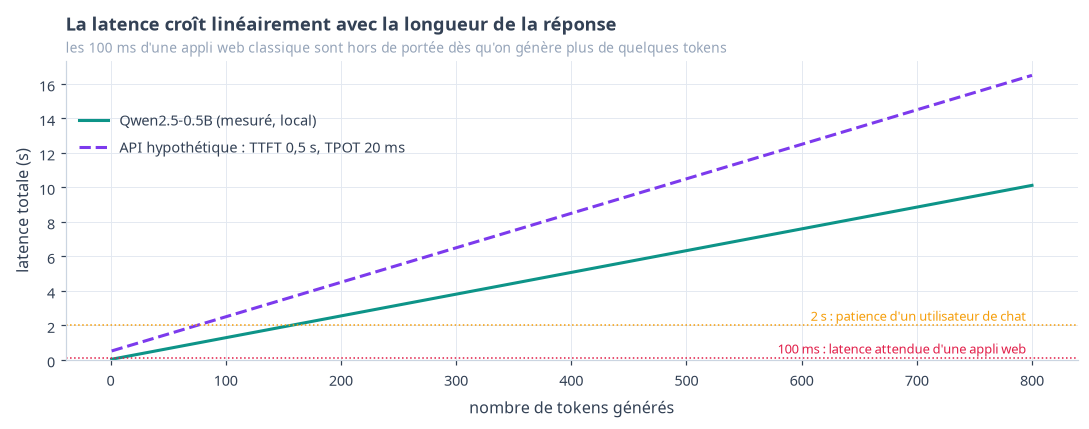

In [13]:
lat = c1.measure_latency(llm.SMALL, prompt="Explique en détail ce qu'est un token.", n_out=64, repeats=3)
print(f"TTFT ≈ {lat['ttft'] * 1000:.0f} ms (prompt de {lat['n_prompt']} tokens), "
      f"TPOT ≈ {lat['tpot'] * 1000:.1f} ms/token, soit ≈ {1 / lat['tpot']:.0f} tokens/s")

n_out = np.arange(1, 801)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(n_out, c1.generation_latency(n_out, lat["ttft"], lat["tpot"]), color=TEAL, label="Qwen2.5-0.5B (mesuré, local)")
ax.plot(n_out, c1.generation_latency(n_out, 0.5, 0.02), color=VIOLET, ls="--", label="API hypothétique : TTFT 0,5 s, TPOT 20 ms")
for y, lab, col in [(0.1, "100 ms : latence attendue d'une appli web", ROSE), (2.0, "2 s : patience d'un utilisateur de chat", AMBER)]:
    ax.axhline(y, color=col, lw=1, ls=":")
    ax.text(795, y + 0.25, lab, color=col, ha="right", fontsize=8.5)
ax.set_ylim(0, None)
ax.set_xlabel("nombre de tokens générés"); ax.set_ylabel("latence totale (s)")
ax.legend(loc="upper left", bbox_to_anchor=(0.0, 0.88))
c1.title_sub(ax, "La latence croît linéairement avec la longueur de la réponse",
             "les 100 ms d'une appli web classique sont hors de portée dès qu'on génère plus de quelques tokens")
plt.tight_layout(); plt.show()

Le livre insiste : le seuil acceptable dépend du contexte. Si les demandes clients sont
aujourd'hui traitées par des humains en une heure (médiane), même 10 secondes est un
progrès spectaculaire. Pour un assistant de saisie, chaque centaine de millisecondes
compte. C'est pourquoi on **streame** la réponse (le TTFT devient la latence perçue) et
pourquoi l'optimisation de l'inférence est si importante (chapitre 9).

**Le coût par requête.** Avec des tarifs facturés au million de tokens (entrée et sortie
séparément), on obtient le coût d'une requête puis le coût mensuel. Les tarifs ci-dessous
sont **hypothétiques** (ordre de grandeur d'un petit modèle hébergé en 2024-2025) :
consultez toujours la grille à jour de votre fournisseur.

coût d'une requête : 0.405 millième de dollar (0.00040 $)


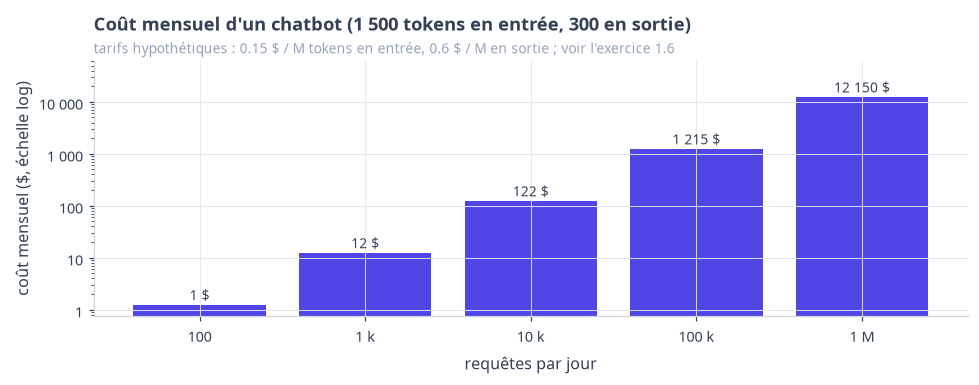

In [14]:
price_in, price_out = 0.15, 0.60      # $ par million de tokens (hypothèse)
n_in, n_out_req = 1_500, 300          # prompt système + historique + question ; réponse
per_req = c1.request_cost(n_in, n_out_req, price_in, price_out)
traffic = np.array([1e2, 1e3, 1e4, 1e5, 1e6])
monthly = [c1.monthly_cost(t, n_in, n_out_req, price_in, price_out) for t in traffic]
print(f"coût d'une requête : {per_req * 1000:.3f} millième de dollar ({per_req:.5f} $)")
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar([c1.human_number(t) for t in traffic], monthly, color=INDIGO)
ax.set_yscale("log"); c1.plain_log(ax)
for i, m in enumerate(monthly):
    ax.text(i, m * 1.25, f"{m:,.0f} $".replace(",", " "), ha="center", fontsize=9)
ax.set_xlabel("requêtes par jour"); ax.set_ylabel("coût mensuel ($, échelle log)")
ax.set_ylim(top=max(monthly) * 5)
c1.title_sub(ax, "Coût mensuel d'un chatbot (1 500 tokens en entrée, 300 en sortie)",
             f"tarifs hypothétiques : {price_in} \\$ / M tokens en entrée, {price_out} \\$ / M en sortie ; voir l'exercice 1.6")
plt.tight_layout(); plt.show()

> **À retenir.** Une bonne définition du succès part de la métrique métier, puis fixe un
> seuil d'utilité mesurable : qualité, latence (TTFT + $n \times$ TPOT), coût par requête.
> Le seuil acceptable dépend de la situation actuelle (souvent un processus humain lent).

## 6. Planifier les jalons : le dernier kilomètre (section *Milestone Planning*)

**Partir de l'existant.** On évalue d'abord les modèles disponibles : si l'objectif est
d'automatiser 60 % des tickets et qu'un modèle prêt à l'emploi en automatise déjà 30 %,
le chemin est plus court. Il arrive aussi que l'évaluation montre que l'effort dépasse le
gain attendu, et qu'on renonce.

**Le piège de la démo.** Le livre cite l'article UltraChat : aller de 0 à 60 est facile,
progresser de 60 à 100 devient extrêmement difficile. LinkedIn (2024) a atteint 80 % de
l'expérience visée en **un mois**, puis il a fallu **quatre mois de plus** pour dépasser
95 %. Modélisons ce phénomène.

- Modèle naïf : l'écart restant décroît **exponentiellement**,
  $q(t) = 100\,(1 - e^{-t/\tau})$. Calé sur « 80 % en un mois », il prédit 95 % en moins de
  deux mois.
- Modèle « dernier kilomètre » : l'erreur restante décroît en **loi de puissance**,
  $e(t) = 100 - q(t) = a\,t^{-b}$. Deux points suffisent à l'ajuster (en échelle log-log,
  c'est une droite) : $a = 20$ et $b = \ln 4 / \ln 5 \approx 0{,}86$.

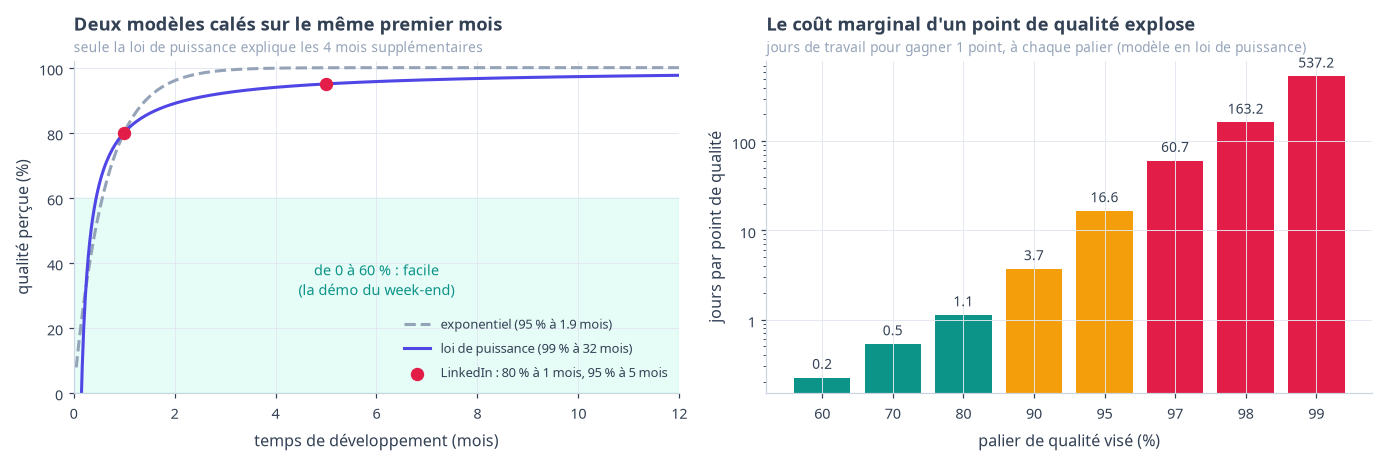

In [15]:
a, b = c1.fit_power_law_error([1, 5], [80, 95])
tau = -1 / np.log(0.2)                       # 100 (1 - e^{-1/tau}) = 80
t = np.linspace(0.05, 12, 400)
t_exp95 = -tau * np.log(0.05)
t99 = c1.time_to_quality(99, a, b)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
ax = axes[0]
ax.plot(t, c1.quality_exponential(t, tau=tau), color=GRAY, ls="--", label=f"exponentiel (95 % à {t_exp95:.1f} mois)")
ax.plot(t, c1.quality_power_law(t, a, b), color=INDIGO, label=f"loi de puissance (99 % à {t99:.0f} mois)")
ax.scatter([1, 5], [80, 95], color=ROSE, zorder=5, s=60, label="LinkedIn : 80 % à 1 mois, 95 % à 5 mois")
ax.axhspan(0, 60, color=LIGHT[TEAL], alpha=0.5)
ax.text(6, 30, "de 0 à 60 % : facile\n(la démo du week-end)", color=TEAL, fontsize=9.5, ha="center")
ax.set_ylim(0, 102); ax.set_xlim(0, 12)
ax.set_xlabel("temps de développement (mois)"); ax.set_ylabel("qualité perçue (%)")
ax.legend(loc="lower right", fontsize=8.5)
c1.title_sub(ax, "Deux modèles calés sur le même premier mois", "seule la loi de puissance explique les 4 mois supplémentaires")
ax = axes[1]
targets = np.array([60, 70, 80, 90, 95, 97, 98, 99])
times = np.array([c1.time_to_quality(q, a, b) for q in targets])
marg = np.diff(np.r_[0, times]) / np.diff(np.r_[0, targets])
ax.bar([f"{q}" for q in targets], marg * 30, color=[TEAL] * 3 + [AMBER] * 2 + [ROSE] * 3)
ax.set_yscale("log"); c1.plain_log(ax)
ax.set_xlabel("palier de qualité visé (%)"); ax.set_ylabel("jours par point de qualité")
annotate_bars(ax, "{:.1f}")
c1.title_sub(ax, "Le coût marginal d'un point de qualité explose", "jours de travail pour gagner 1 point, à chaque palier (modèle en loi de puissance)")
finish(fig); plt.show()

Sous le modèle en loi de puissance, chaque point supplémentaire coûte de plus en plus cher :
quelques heures autour de 60 %, deux semaines par point vers 95 %, deux mois par point vers
97 %, et viser 99 % prendrait plus de deux ans et demi à ce rythme. D'où trois conseils de planification : ne pas extrapoler
le rythme de la démo, fixer le seuil d'utilité **avant** de commencer, et prévoir que le
« dernier kilomètre » (cas limites, hallucinations) consomme l'essentiel du calendrier.

> **À retenir.** Une démo réussie ne prédit pas un bon produit : la qualité progresse vite
> au début puis l'erreur restante décroît lentement (loi de puissance). Planifiez avec un
> modèle réaliste du dernier kilomètre (exercice 1.9).

## 7. La maintenance dans un domaine qui bouge vite (section *Maintenance*)

Construire sur des modèles de fondation, dit le livre, c'est monter dans un train lancé à
pleine vitesse. Beaucoup de changements sont positifs (contextes plus longs, modèles
meilleurs, inférence plus rapide et moins chère), mais même eux créent des frictions : la
meilleure option d'aujourd'hui peut devenir la pire demain. Exemple du livre : on décide
d'héberger un modèle en interne parce que c'est moins cher que l'API... et trois mois plus
tard, le fournisseur divise ses prix par deux. Simulons.

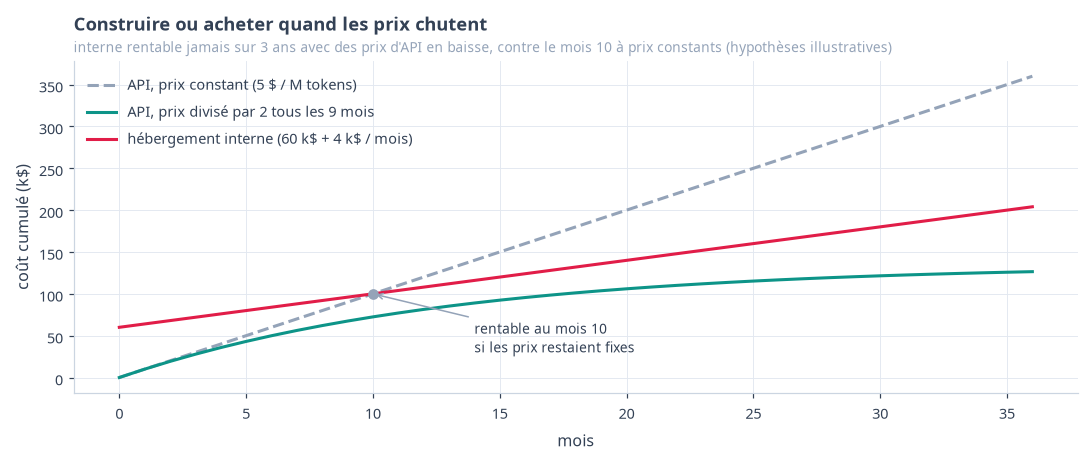

In [16]:
months = 36
tokens_m = 2_000                      # millions de tokens par mois
api_flat = c1.api_cumulative_cost(months, tokens_m, 5.0)
api_falling = c1.api_cumulative_cost(months, tokens_m, 5.0, halving_months=9)
inhouse = c1.inhouse_cumulative_cost(months, upfront=60_000, monthly=4_000)
be_flat, be_fall = c1.break_even_month(api_flat, inhouse), c1.break_even_month(api_falling, inhouse)
fig, ax = plt.subplots(figsize=(10, 4.3))
m = np.arange(months + 1)
ax.plot(m, api_flat / 1000, color=GRAY, ls="--", label="API, prix constant (5 $ / M tokens)")
ax.plot(m, api_falling / 1000, color=TEAL, label="API, prix divisé par 2 tous les 9 mois")
ax.plot(m, inhouse / 1000, color=ROSE, label="hébergement interne (60 k\\$ + 4 k\\$ / mois)")
if be_flat:
    ax.scatter([be_flat], [inhouse[be_flat] / 1000], color=GRAY, zorder=5)
    ax.annotate(f"rentable au mois {be_flat}\nsi les prix restaient fixes", (be_flat, inhouse[be_flat] / 1000),
                xytext=(be_flat + 4, inhouse[be_flat] / 1000 - 70), fontsize=9, arrowprops=dict(arrowstyle="->", color=GRAY))
ax.set_xlabel("mois"); ax.set_ylabel("coût cumulé (k$)")
ax.legend(loc="upper left")
c1.title_sub(ax, "Construire ou acheter quand les prix chutent",
             "interne rentable " + (f"au mois {be_fall}" if be_fall else "jamais sur 3 ans") +
             " avec des prix d'API en baisse, contre le mois " + str(be_flat) + " à prix constants (hypothèses illustratives)")
plt.tight_layout(); plt.show()

Avec des prix constants, l'hébergement interne serait rentabilisé en moins d'un an ; avec
des prix d'API divisés par deux tous les neuf mois (rythme plausible au vu de l'historique
récent), il ne l'est jamais sur trois ans. L'exercice 1.10 explore la sensibilité à ces
hypothèses.

**Autres sources de changement.** Les API des fournisseurs convergent, ce qui facilite le
remplacement d'un modèle par un autre, mais chaque modèle a ses particularités : il faut
réajuster prompts et données, d'où l'importance d'une infrastructure de **versionnage** et
d'**évaluation**. Les changements réglementaires sont plus durs (le RGPD aurait coûté
9 Md$ de mise en conformité aux entreprises ; l'accès aux GPU peut être restreint du jour
au lendemain), et certains peuvent être fatals (propriété intellectuelle des modèles
entraînés sur les données d'autrui).

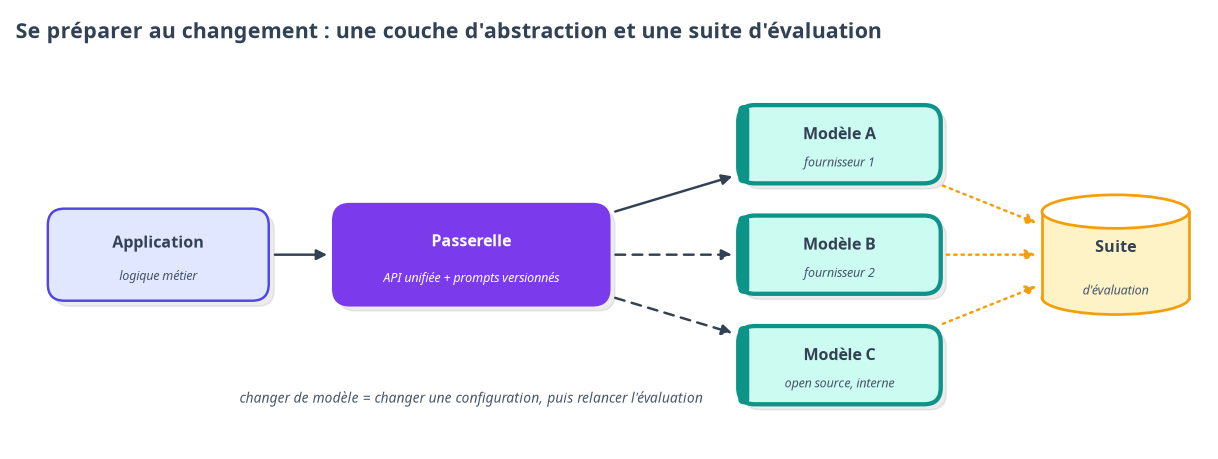

In [17]:
d = Diagram(13, 4.2, title="Se préparer au changement : une couche d'abstraction et une suite d'évaluation")
d.box("app", 1.6, 2.1, "Application", sub="logique métier", color=INDIGO, w=2.4, h=1.0)
d.box("gw", 5.0, 2.1, "Passerelle", sub="API unifiée + prompts versionnés", color=VIOLET, w=3.0, h=1.1, filled=True)
d.box("ma", 9.0, 3.3, "Modèle A", sub="fournisseur 1", color=TEAL, kind="model", w=2.2, h=0.85)
d.box("mb", 9.0, 2.1, "Modèle B", sub="fournisseur 2", color=TEAL, kind="model", w=2.2, h=0.85)
d.box("mc", 9.0, 0.9, "Modèle C", sub="open source, interne", color=TEAL, kind="model", w=2.2, h=0.85)
d.box("ev", 12.0, 2.1, "Suite", sub="d'évaluation", color=AMBER, kind="db", w=1.6, h=1.3)
d.arrow("app", "gw")
for k in ["ma", "mb", "mc"]:
    d.arrow("gw", k, style="solid" if k == "ma" else "dashed")
    d.arrow(k, "ev", style="dotted", color=AMBER)
d.note(5.0, 0.55, "changer de modèle = changer une configuration, puis relancer l'évaluation", fontsize=9)
d.show()

> **À retenir.** La maintenance d'un produit d'IA impose une analyse coût-bénéfice
> permanente : prix, modèles et réglementation changent vite. Une couche d'abstraction et
> une suite d'évaluation automatisée rendent ces changements absorbables.

## Synthèse

- **Cas d'usage** : huit familles ; l'IA excelle dans les tâches de langage et
  d'information ; les entreprises commencent par l'interne et le fermé, plus faciles à
  évaluer.
- **Évaluer le cas d'usage** : pourquoi (menace, opportunité, exploration), quel rôle pour
  l'IA (critique/complémentaire, réactive/proactive, dynamique/statique), quel rôle pour
  l'humain (*Crawl-Walk-Run*, décisions appuyées sur des intervalles de confiance).
- **Défendabilité** : la technologie est partagée ; les données d'usage et la
  distribution font la différence.
- **Attentes** : métrique métier, puis seuil d'utilité (qualité, latence
  TTFT + $n \cdot$ TPOT, coût par requête).
- **Jalons** : le dernier kilomètre suit une loi de puissance ; chaque point coûte plus
  cher que le précédent.
- **Maintenance** : prix en baisse rapide, modèles interchangeables mais capricieux,
  réglementation mouvante : il faut versionner et évaluer en continu.

**Liens.** Les chapitres 3 et 4 détaillent l'évaluation (métriques, construction d'un
pipeline d'évaluation), le chapitre 9 la latence et le coût d'inférence, le chapitre 10
l'architecture et les retours utilisateurs. Le cours 4 présente la **pile** de l'AI
engineering.

In [18]:
llm.free_gpu()